# Evidencia de aprendizaje 1 — Análisis y herramientas de extracción de datos
**Integrantes:** Simón Castaño Ríos · Juan Pablo Gonzalez Gil · Luisa Fernanda Gómez Quiroz

**Curso:** Programación para Análisis de Datos — Grupo PREICA2602B020048 · **Docente:** Andrés Felipe Palacio · IU Digital

**Artículo:** HSHFKLH – 3 piezas de arte de pared de lienzo de mujeres afroamericanas
(Amazon, ASIN `B0D21SJ6BR`) · https://www.amazon.com/dp/B0D21SJ6BR

Se extrae la misma ficha de producto con los tres métodos vistos en la Unidad 1 y se comparan los resultados.

| Método | Cómo obtiene la página | Archivo |
|---|---|---|
| BeautifulSoup | Petición HTTP con `requests`; analiza el HTML | `scraping/scraper_beautifulsoup.py` |
| Selenium | Controla un Chrome real y lee el DOM renderizado | `scraping/scraper_selenium.py` |
| Scrapy | Spider con selectores CSS/XPath, robots.txt y *feeds* | `scraping/scraper_scrapy.py` |

## 0. Preparación

In [1]:
# Ejecutar una sola vez si faltan librerías:
# %pip install -r scraping/requirements.txt

import json, re, subprocess, sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CARPETA = Path.cwd() / "scraping"
sys.path.insert(0, str(CARPETA))
from comun import DATA_DIR, URL

def ejecutar(script, *args):
    """Ejecuta un scraper como proceso aparte y muestra su salida."""
    r = subprocess.run([sys.executable, "-X", "utf8", script, *args], cwd=CARPETA,
                       capture_output=True, text=True, encoding="utf-8")
    print(r.stdout)
    avisos = [l for l in r.stderr.splitlines() if "WARNING" in l or "Error" in l]
    print("\n".join(avisos))

print(URL)

https://www.amazon.com/dp/B0D21SJ6BR


## 1. BeautifulSoup + requests
Una sola petición GET con encabezados de navegador. BeautifulSoup recorre el HTML con selectores CSS (`#productTitle`, `#acrPopover`, `[data-hook="review"]`...). También guarda el HTML en `data/pagina_amazon.html`.

In [2]:
ejecutar("scraper_beautifulsoup.py")

[BeautifulSoup] 2.67 s · fuente: en vivo
  Título       : HSHFKLH 3 piezas de arte de pared de lienzo de mujeres afroamericanas de 12
  Precio       : 94633.44 COP
  Calificación : 4.8 (104 calificaciones)
  Tienda       : HSHFKLH
  Histograma % : {'5': 91, '4': 5, '3': 1, '2': 0, '1': 3}
  Reseñas      : 8
Guardado en C:\Users\casta\OneDrive\Escritorio\iu digital analsis de datos\scraping\data\producto_bs4.json




## 2. Selenium
Abre Chrome, espera (con `WebDriverWait`) a que aparezca el título, baja hasta las reseñas para que carguen y toma una captura. Aquí se usa `--headless`; si Amazon pide una verificación, ejecutar `python scraper_selenium.py` en una terminal (con ventana) y completarla a mano.

In [3]:
ejecutar("scraper_selenium.py", "--headless")

[Selenium] 8.83 s · fuente: en vivo
  Título       : HSHFKLH 3 piezas de arte de pared de lienzo de mujeres afroamericanas de 12
  Precio       : 94633.44 COP
  Calificación : 4.8 (104 calificaciones)
  Tienda       : HSHFKLH
  Histograma % : {'5': 91, '4': 5, '3': 1, '2': 0, '1': 3}
  Reseñas      : 8
Guardado en C:\Users\casta\OneDrive\Escritorio\iu digital analsis de datos\scraping\data\producto_selenium.json




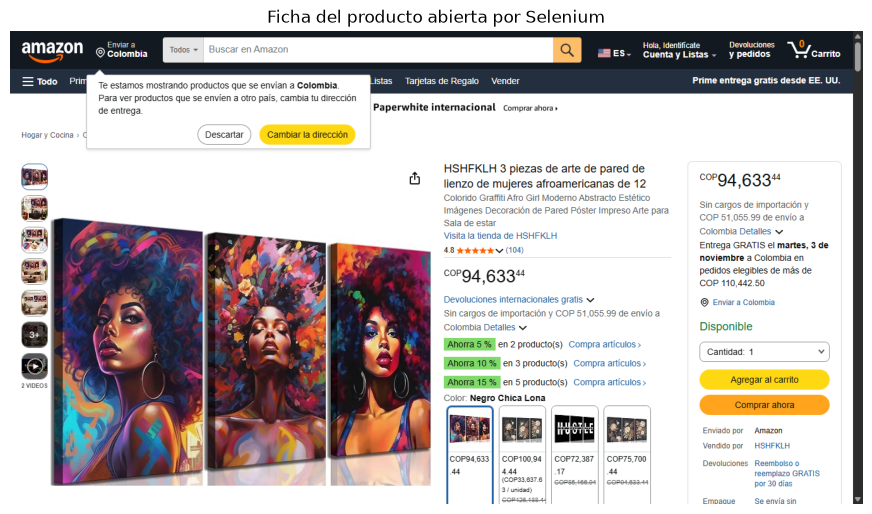

In [4]:
plt.figure(figsize=(11, 7))
plt.imshow(plt.imread(DATA_DIR / "captura_selenium.png")); plt.axis("off")
plt.title("Ficha del producto abierta por Selenium"); plt.show()

## 3. Scrapy
El spider respeta `robots.txt` (la ruta `/dp/` está permitida), aplica un retardo de 2 s y exporta con `FEEDS`. Si Amazon le responde con un captcha, lo registra y procesa el HTML guardado en el paso 1 — el campo `fuente` lo indica.

In [5]:
ejecutar("scraper_scrapy.py")

Guardado en C:\Users\casta\OneDrive\Escritorio\iu digital analsis de datos\scraping\data\producto_scrapy.json

2026-10-24 19:26:29 [producto_amazon] WARNING: Amazon respondió con un captcha a Scrapy (HTTP 200).
2026-10-24 19:26:29 [producto_amazon] WARNING: Se procesa la copia guardada: pagina_amazon.html


## 4. Comparación de los tres métodos

In [6]:
from comparar_resultados import cargar, tabla_comparativa, tabla_resenas

registros = cargar()
comparacion = tabla_comparativa(registros)
comparacion.to_csv(DATA_DIR / "comparacion_metodos.csv", index=False, encoding="utf-8-sig")
comparacion.set_index("metodo").T

metodo,BeautifulSoup,Selenium,Scrapy
fuente,en vivo,en vivo,HTML guardado (captcha en vivo)
tiempo_seg,2.67,8.83,4.57
campos_ok,7/7,7/7,7/7
titulo,HSHFKLH 3 piezas de arte de pared de lienzo de...,HSHFKLH 3 piezas de arte de pared de lienzo de...,HSHFKLH 3 piezas de arte de pared de lienzo de...
precio_cop,94633.44,94633.44,94633.44
calificacion,4.8,4.8,4.8
num_calificaciones,104,104,104
tienda,HSHFKLH,HSHFKLH,HSHFKLH
disponibilidad,Disponible,Disponible,Disponible
categoria,Hogar y Cocina › Obras de Arte y Material Deco...,Hogar y Cocina › Obras de Arte y Material Deco...,Hogar y Cocina › Obras de Arte y Material Deco...


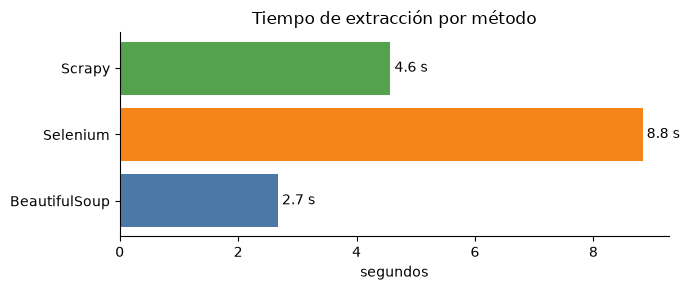

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
barras = ax.barh(comparacion["metodo"], comparacion["tiempo_seg"], color=["#4C78A8", "#F58518", "#54A24B"])
ax.bar_label(barras, fmt="%.1f s", padding=3)
ax.set_xlabel("segundos"); ax.set_title("Tiempo de extracción por método")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 5. Datos del artículo

In [8]:
p = registros[0]
ficha = pd.Series({
    "Título": p["titulo"],
    "Precio (COP)": f"${p['precio_cop']:,.0f}",
    "Calificación": f"{p['calificacion']} de 5",
    "N.º de calificaciones": p["num_calificaciones"],
    "Tienda": p["tienda"],
    "Disponibilidad": p["disponibilidad"],
    "Categoría": p["categoria"],
}, name="valor")
ficha.to_frame()

,valor
Título,HSHFKLH 3 piezas de arte de pared de lienzo de...
Precio (COP),"$94,633"
Calificación,4.8 de 5
N.º de calificaciones,104
Tienda,HSHFKLH
Disponibilidad,Disponible
Categoría,Hogar y Cocina › Obras de Arte y Material Deco...


In [9]:
for i, c in enumerate(p["caracteristicas"], 1):
    print(f"{i}. {c[:160]}")

1. Lienzo de mujeres afroamericanas para pared: Disponible en tamaños de 12x16 pulgadas y 16x24 pulgadas. Cuenta con un marco de madera resistente, no requiere mon
2. Decoración abstracta de pared de niña africana: el arte de pared en lienzo de niña negra puede agregar estilo de moda a tu espacio vital, alegrar tu espacio e i
3. Obra de arte de mujeres negras: Mujer afroamericana abstracta, una gran opción para la decoración del hogar, como decoración de pared para sala de estar, dormit
4. Arte de mujer negra: Pintura de lienzo de mujer colorida para el hogar También puede traer grandes ideas a tu familia, amigos y parejas en cumpleaños, bodas, an
5. Servicio posventa: si estás insatisfecho con las decoraciones de pared de mujeres afroamericanas de cualquier manera después de recibirlas, por favor no dudes e


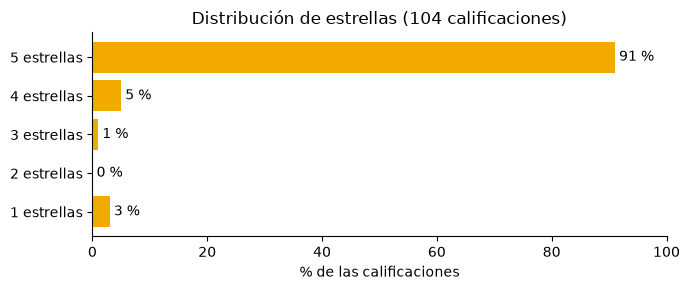

Calificaciones de 4-5 estrellas: 96 %  ·  1-2 estrellas: 3 %


In [10]:
hist = pd.Series(p["histograma_pct"]).sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
barras = ax.barh([f"{e} estrellas" for e in hist.index], hist.values, color="#F2A900")
ax.bar_label(barras, fmt="%d %%", padding=3)
ax.set_xlim(0, 100); ax.set_xlabel("% de las calificaciones")
ax.set_title(f"Distribución de estrellas ({p['num_calificaciones']} calificaciones)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

print(f"Calificaciones de 4-5 estrellas: {hist.get('5', 0) + hist.get('4', 0)} %  ·  "
      f"1-2 estrellas: {hist.get('1', 0) + hist.get('2', 0)} %")

## 6. Reseñas destacadas

Amazon a veces muestra las reseñas destacadas sin iniciar sesión y otras veces pide *Identifícate para ver las opiniones*. Se usa el método que haya obtenido más reseñas.

In [11]:
p_res = max(registros, key=lambda r: len(r["resenas"]))
resenas = tabla_resenas(p_res)
if resenas.empty:
    print("En esta ejecución Amazon pidió iniciar sesión para ver el texto de las reseñas.")
else:
    resenas.to_csv(DATA_DIR / "resenas.csv", index=False, encoding="utf-8-sig")
    print(f"{len(resenas)} reseñas (método: {p_res['metodo']})")
resenas

8 reseñas (método: BeautifulSoup)


,titulo,estrellas,fecha,texto
0,Love it!,5,2 de agosto de 2026,The colors and picture look’s just as advertis...
1,Black Art,5,24 de julio de 2025,"Vibrant colors, and the size is perfect. Every..."
2,Gorgeous 🥰,5,5 de mayo de 2026,Just what I needed to complete the look.
3,I am in Love with these paintings!,5,25 de abril de 2025,I am in love with these paintings. They are so...
4,I love it!,5,31 de agosto de 2025,Another good addition to my bedroom. Pops of c...
5,Beautiful art work,5,19 de mayo de 2025,Beautiful really brought my living room to lif...
6,Beautiful,5,5 de enero de 2025,I was on the fence about buying these pictures...
7,Beautiful Artwork,5,1 de septiembre de 2025,Amazing Artwork! Perfect for my Hair Dryer Roo...


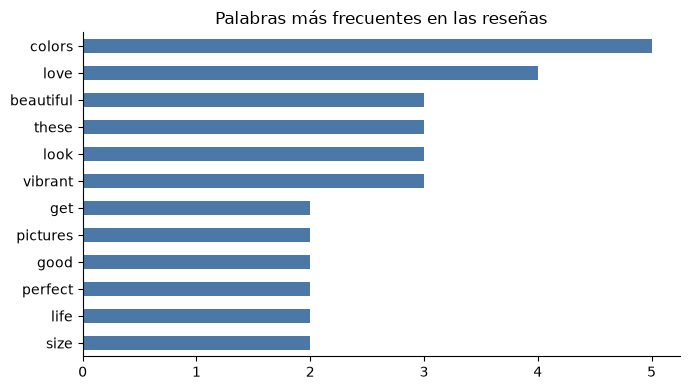

In [12]:
vacias = set("the and i a to it is of in my for this was they are so them with on as be have very just what you will that".split())
if not resenas.empty:
    palabras = Counter(w for t in resenas["texto"] for w in re.findall(r"[a-záéíóúñ]+", t.lower())
                       if w not in vacias and len(w) > 2)
    top = pd.Series(dict(palabras.most_common(12))).sort_values()
    ax = top.plot.barh(figsize=(7, 4), color="#4C78A8", title="Palabras más frecuentes en las reseñas")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()

## 7. Conclusiones
* Los tres métodos obtuvieron **los mismos 7 campos** del producto ; cuando Amazon muestra las reseñas sin iniciar sesión, los tres obtienen las mismas.
* **BeautifulSoup** fue el más rápido y sencillo: Amazon entrega el contenido en el HTML inicial.
* **Selenium** fue el más lento (abre un navegador completo), pero es el más robusto ante contenido dinámico y permite completar a mano una verificación.
* **Scrapy** recibió un captcha en la petición en vivo; el spider lo detectó y procesó el HTML guardado. Para escalar a muchos productos ofrece la mejor estructura (robots.txt, retardos, exportación).
* El artículo tiene una percepción muy positiva (4,8/5; más del 90 % de 5 estrellas) ; las reseñas destacan colores vivos, tamaño y calidad.
* Siguiente paso (unidades 2 y 3): ampliar a varios cuadros similares y seguir el precio en el tiempo.